# Carrier-assisted entanglement purification: code for the figures

This notebook reproduces the numerical figures of

J. Kim, K. Mohan, S. W. Yun, and J. Bae, "Carrier-Assisted Entanglement Purification," *IEEE Journal on Selected Areas in Communications*, vol. 44, pp. 5311–5326, 2026, [doi:10.1109/JSAC.2026.3710152](https://doi.org/10.1109/JSAC.2026.3710152), [arXiv:2509.07514](https://arxiv.org/abs/2509.07514).

Equation, figure, and section numbers refer to the published version.
In arXiv v5, the appendix equations (37), (42)–(44), (53), (54), and (56) are numbered (A5), (A10)–(A12), (A21), (A22), and (A24).
Figures 1, 5, 9, and 10 are circuit diagrams and are not generated here.

**How to run.** The notebook needs Python 3 with NumPy and Matplotlib.
It was tested with Python 3.13, NumPy 2.5.3, and Matplotlib 3.11.2.
Run all cells in order, in Jupyter or Google Colab.
Each figure is shown and saved as a 600-dpi PNG file named after its figure number, for example `fig2a.png`.

**Conventions.**
- A Bell-diagonal state is given by $q = (q_{00}, q_{01}, q_{10}, q_{11})$, the weights of $(\phi^+, \phi^-, \psi^+, \psi^-)$ in Eq. (5). Its entanglement fidelity is $F = q_{00}$, Eq. (4).
- A Pauli channel is given by $(p_{00}, p_{01}, p_{10}, p_{11})$, the probabilities of $I$, $Z$, $X$, and $Y$ in Eq. (2). Sending one half of $\phi^+$ through it gives $q = (p_{00}, p_{01}, p_{10}, p_{11})$.
- Pre-processing with $R_X(+\pi/2) \otimes R_X(-\pi/2)$ swaps $q_{01}$ and $q_{11}$, see Eq. (7).

| Figure | Section of this notebook | Model |
| --- | --- | --- |
| 2, 3, 4 | Single carrier | One-round map of Eq. (13) |
| 6, 7 | Multiple carriers | Map of Eq. (54) and the pairwise code of Fig. 7(c) |
| 8 | Multiple carriers | Fixed point of Eq. (53), given by Eq. (56) |
| 11 | Noisy local operations | Density matrices of one round, Fig. 10 |

If you use this code, please cite the paper.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator

p00_vals = np.linspace(0.5, 1.0, 101)   # grid of channel fidelities p00 for Figs. 2-7

## Single carrier (Figs. 2–4)

One successful round maps $q$ to $Lq / \mathbf{1}^\top Lq$ and succeeds with probability $\mathbf{1}^\top Lq$, Eq. (13).
The code builds $L$ as $MP$, where $P$ is the pre-processing swap and $M$ is the map of the $ZZ$ check: CNOT encoding, carrier transmission, CNOT decoding, and outcome 0.
Without pre-processing, as for the flip channel of Fig. 4, $L = M$.
The maximum convergent fidelity $F_\star$ is the first entry of the dominant eigenvector of $L$, normalized to unit sum.
The total success probability after $n$ rounds is the product of the success probabilities of rounds 1 to $n$, Eq. (18).

In [2]:
def prerotation_swap_matrix():
    # Pre-processing R_X(+pi/2) x R_X(-pi/2): swaps q01 <-> q11 in q = [q00, q01, q10, q11]
    P = np.eye(4)
    P[[1, 3], :] = P[[3, 1], :]
    return P

def zz_update_matrix(pI, pZ, pX, pY):
    # Unnormalized single-carrier ZZ-check map in Bell coefficients (without pre-processing)
    return np.array([
        [pI, pZ, 0.0, 0.0],
        [pZ, pI, 0.0, 0.0],
        [0.0, 0.0, pX, pY],
        [0.0, 0.0, pY, pX],
    ], dtype=float)

def one_round(q, L):
    # One successful round: normalized Bell coefficients and success probability
    t = L @ q
    p_succ = float(np.sum(t))
    return t / p_succ, p_succ

def fixed_point(L):
    # Dominant right eigenvector of L, normalized: the fixed point of the normalized iteration
    vals, vecs = np.linalg.eig(L)
    k = int(np.argmax(np.real(vals)))
    v = np.real(vecs[:, k])
    if np.sum(v) < 0:
        v = -v
    v = np.maximum(v, 0.0)
    return v / np.sum(v)

def sweep(L_list, q0_list, max_round):
    # For each p00 in p00_vals: fidelity F[i, n] and success probability P[i, n] of rounds n = 0..max_round
    # (P[i, 0] is undefined), and the maximum convergent fidelity F_conv[i]
    F, P, F_conv = [], [], []
    for L, q in zip(L_list, q0_list):
        F_traj, P_traj = [q[0]], [np.nan]
        for n in range(max_round):
            q, p_succ = one_round(q, L)
            F_traj.append(q[0])
            P_traj.append(p_succ)
        F.append(F_traj)
        P.append(P_traj)
        F_conv.append(fixed_point(L)[0])
    return np.array(F), np.array(P), np.array(F_conv)

In [3]:
def plot_fidelity_vs_p00(F, rounds, F_conv, title, filename,
                         label_round0=True, ylabel='Entanglement Fidelity', legend_kw=None):
    # Fidelity vs p00 after the listed rounds and at convergence, with dots at p00 = 0.75
    plt.figure(figsize=(6, 5))
    curves = [] if F_conv is None else [('Convergence', F_conv)]
    curves += [(f'Round {r}', F[:, r]) for r in rounds]
    lines = [plt.plot(p00_vals, y, label=lbl)[0] for lbl, y in curves]
    lines.append(plt.plot(p00_vals, F[:, 0], '--', color='black',
                          label='Round 0' if label_round0 else None)[0])
    curves.append(('Round 0', F[:, 0]))

    i0 = int(np.argmin(np.abs(p00_vals - 0.75)))
    x0 = p00_vals[i0]
    plt.axvline(x=x0, linestyle=':', color='black', linewidth=1)
    for line, (lbl, y) in zip(lines, curves):
        plt.plot([x0], [y[i0]], 'o', markersize=4, color=line.get_color(), zorder=6)
    print(f'p00 = {x0:.2f}: ' + ', '.join(f'{lbl} {y[i0]:.6f}' for lbl, y in curves))

    plt.xlabel(r'$p_{00}$')
    plt.ylabel(ylabel)
    plt.title(title)
    plt.legend(**(legend_kw or {}))
    plt.grid(True)
    plt.savefig(filename, bbox_inches='tight', dpi=600)
    plt.show()

def plot_fidelity_and_total_success(F, P, F_conv, title, filename,
                                    p00_targets=(0.85, 0.75, 0.65, 0.55), max_round=4):
    # Fidelity (solid) and total success probability (dashed, Eq. (18)) vs round, F_conv at "infinity"
    rounds = np.arange(0, max_round + 1)
    x_inf = max_round + 1
    fig, ax = plt.subplots(figsize=(6, 5))
    for t in p00_targets:
        i = int(np.argmin(np.abs(p00_vals - t)))
        F_traj = F[i, rounds]
        Y_traj = np.cumprod(np.r_[1.0, P[i, 1:max_round + 1]])
        (lineF,) = ax.plot(rounds, F_traj, linestyle='-', marker='o')
        ax.plot([x_inf], [F_conv[i]], linestyle='None', marker='o', color=lineF.get_color())
        ax.plot(rounds, Y_traj, linestyle='--', marker='*', color=lineF.get_color())
        print(f'p00 = {p00_vals[i]:.2f}: fidelity after round {max_round} = {F_traj[-1]:.4f}, '
              f'total success probability = {Y_traj[-1]:.4f}, F_star = {F_conv[i]:.4f}')
    ax.set_xticks(list(rounds) + [x_inf])
    ax.set_xticklabels([str(r) for r in rounds] + [r'$\infty$'])
    ax.set_xlabel('Round')
    ax.set_ylabel('Entanglement Fidelity / Total Success Probability')
    ax.set_ylim(0.0, 1.0)
    ax.grid(True)
    ax.set_xlim(-0.2, x_inf + 0.4)
    plt.title(title)
    plt.savefig(filename, bbox_inches='tight', dpi=600)
    plt.show()

### Fig. 2: depolarizing channel

p00 = 0.75: Convergence 0.863330, Round 3 0.852041, Round 2 0.840909, Round 1 0.788462, Round 0 0.750000


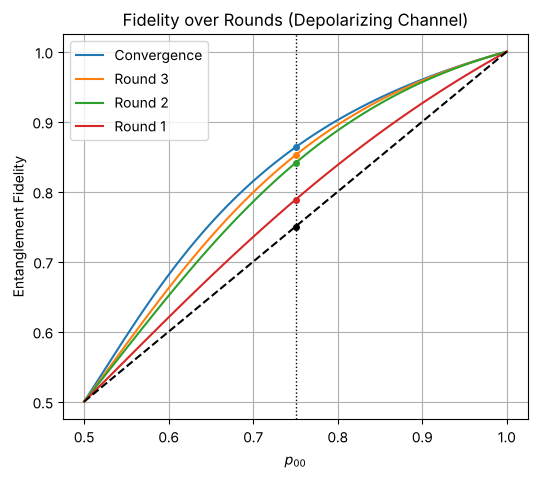

p00 = 0.85: fidelity after round 4 = 0.9334, total success probability = 0.4775, F_star = 0.9341
p00 = 0.75: fidelity after round 4 = 0.8596, total success probability = 0.2816, F_star = 0.8633
p00 = 0.65: fidelity after round 4 = 0.7459, total success probability = 0.1661, F_star = 0.7550
p00 = 0.55: fidelity after round 4 = 0.5871, total success probability = 0.1040, F_star = 0.5939


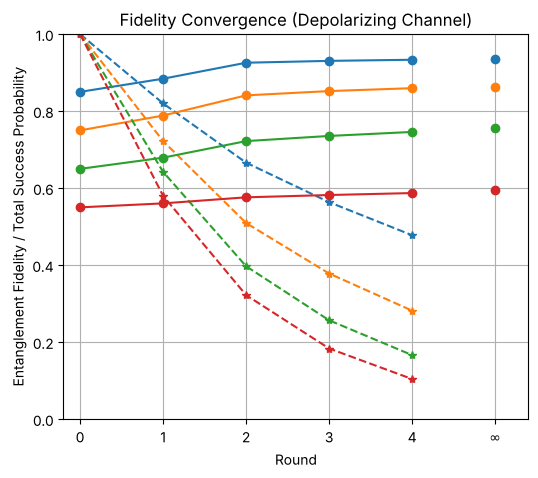

In [4]:
# (p00, p01, p10, p11) = (p00, (1-p00)/3, (1-p00)/3, (1-p00)/3), Eq. (16)
L_list, q0_list = [], []
for p00 in p00_vals:
    p = (1.0 - p00) / 3.0
    q0 = np.array([p00, p, p, p])
    L_list.append(zz_update_matrix(*q0) @ prerotation_swap_matrix())
    q0_list.append(q0)
F, P, F_conv = sweep(L_list, q0_list, max_round=4)

plot_fidelity_vs_p00(F, [3, 2, 1], F_conv, 'Fidelity over Rounds (Depolarizing Channel)', 'fig2a.png',
                     label_round0=False)
plot_fidelity_and_total_success(F, P, F_conv, 'Fidelity Convergence (Depolarizing Channel)', 'fig2b.png')

### Fig. 3: Pauli channel of Eq. (19)

p00 = 0.75: Convergence 0.906707, Round 3 0.885685, Round 2 0.867497, Round 1 0.799296, Round 0 0.750000


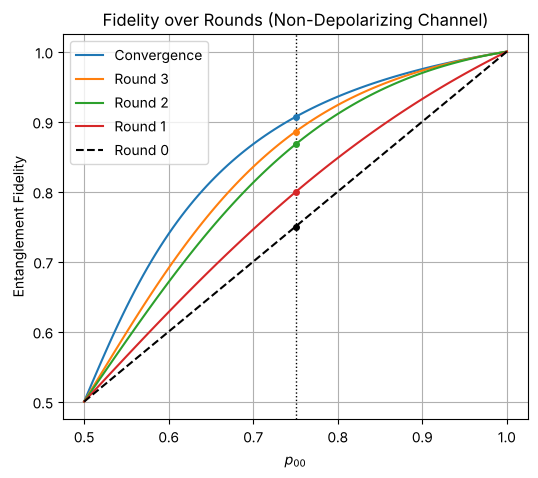

p00 = 0.85: fidelity after round 4 = 0.9565, total success probability = 0.4654, F_star = 0.9579
p00 = 0.75: fidelity after round 4 = 0.8985, total success probability = 0.2677, F_star = 0.9067
p00 = 0.65: fidelity after round 4 = 0.7902, total success probability = 0.1536, F_star = 0.8146
p00 = 0.55: fidelity after round 4 = 0.6093, total success probability = 0.0945, F_star = 0.6349


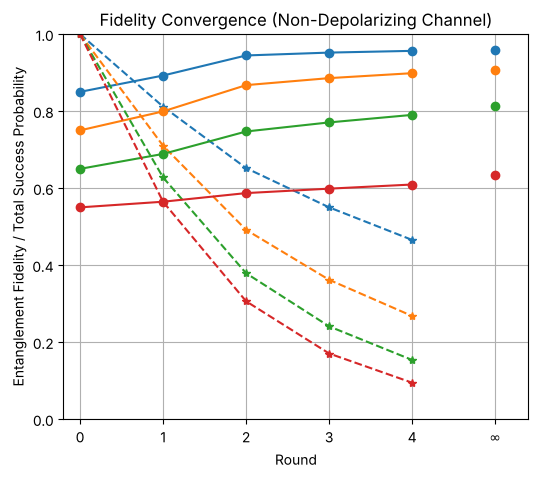

In [5]:
# (p00, p01, p10, p11) = (p00, (1-p00)/5, 2(1-p00)/5, 2(1-p00)/5), Eq. (19)
L_list, q0_list = [], []
for p00 in p00_vals:
    r = 1.0 - p00
    q0 = np.array([p00, (1.0/5.0)*r, (2.0/5.0)*r, (2.0/5.0)*r])
    L_list.append(zz_update_matrix(*q0) @ prerotation_swap_matrix())
    q0_list.append(q0)
F, P, F_conv = sweep(L_list, q0_list, max_round=4)

plot_fidelity_vs_p00(F, [3, 2, 1], F_conv, 'Fidelity over Rounds (Non-Depolarizing Channel)', 'fig3_left.png')
plot_fidelity_and_total_success(F, P, F_conv, 'Fidelity Convergence (Non-Depolarizing Channel)', 'fig3_right.png')

### Fig. 4: flip channel

p00 = 0.75: Round 8 0.999949, Round 7 0.999848, Round 6 0.999543, Round 5 0.998630, Round 4 0.995902, Round 3 0.987805, Round 2 0.964286, Round 1 0.900000, Round 0 0.750000


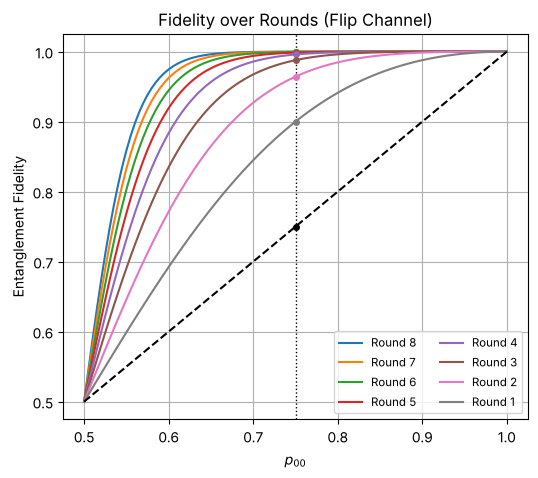

p00 = 0.85: fidelity after round 4 = 0.9998, total success probability = 0.4438, F_star = 1.0000
p00 = 0.75: fidelity after round 4 = 0.9959, total success probability = 0.2383, F_star = 1.0000
p00 = 0.65: fidelity after round 4 = 0.9567, total success probability = 0.1213, F_star = 1.0000
p00 = 0.55: fidelity after round 4 = 0.7317, total success probability = 0.0688, F_star = 1.0000


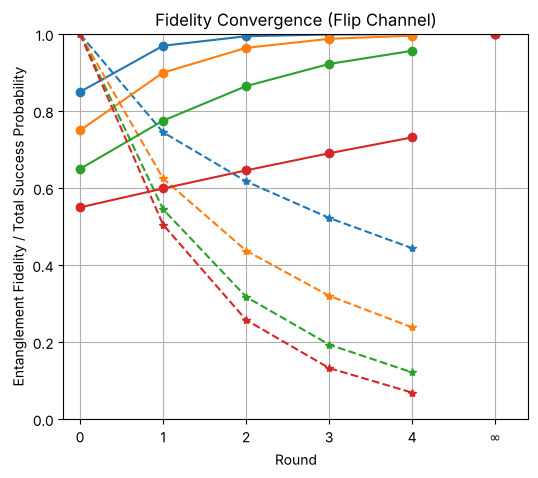

In [6]:
# (p00, p01, p10, p11) = (p00, 0, 1-p00, 0), without pre-processing, so that q01 stays 0
L_list, q0_list = [], []
for p00 in p00_vals:
    q0 = np.array([p00, 0.0, 1.0 - p00, 0.0])
    L_list.append(zz_update_matrix(*q0))
    q0_list.append(q0)
F, P, _ = sweep(L_list, q0_list, max_round=8)   # L is diagonal here, so its eigenvector is not used
F_conv = np.ones(len(p00_vals))                 # F_star = 1 for p00 > 1/2

plot_fidelity_vs_p00(F, list(range(8, 0, -1)), None, 'Fidelity over Rounds (Flip Channel)', 'fig4_left.png',
                     label_round0=False, legend_kw=dict(ncol=2, fontsize='small'))
plot_fidelity_and_total_success(F, P, F_conv, 'Fidelity Convergence (Flip Channel)', 'fig4_right.png')

## Multiple carriers (Figs. 6–8)

For the star checks $\{X_1X_m, \dots, X_{m-1}X_m, Z_0Z_1\cdots Z_m\}$ of Eq. (23) and a depolarizing channel, one round including pre-processing is the map $L_m$ of Eq. (54), with $\alpha$ of Eq. (37) and $A_m$, $B_m$, and $C_m$ of Eqs. (42)–(44).
For $m = 1$ it equals Eq. (13).
The pairwise checks $\{X_1X_2, Z_0Z_1Z_2, X_3X_4, Z_0Z_3Z_4\}$ of Fig. 7(c) give a map with the same pattern of nonzero entries and the coefficients $a$, $b$, and $d$ below.

In [7]:
def L_star(p00, m):
    # Eq. (54): one round with the star checks of Eq. (23) under a depolarizing channel, m >= 1
    a = (4.0*p00 - 1.0)/3.0           # alpha, Eq. (37)
    A = ((1.0 + a)/2.0)**m            # A_m, B_m, C_m, Eqs. (42)-(44)
    B = ((1.0 - a)/2.0)**m
    C = a**m
    return 0.5*np.array([
        [A+C, 0.0, 0.0, B],
        [B,   0.0, 0.0, A+C],
        [0.0, B,   A-C, 0.0],
        [0.0, A-C, B,   0.0],
    ], dtype=float)

def L_pairwise(p00):
    # Pairwise checks {X1X2, Z0Z1Z2, X3X4, Z0Z3Z4} of Fig. 7(c) under a depolarizing channel
    a = (4.0*p00 - 1.0)/3.0
    a_coeff = (13*a**4 + 8*a**3 + 10*a**2 + 1.0)/32.0
    b_coeff = ((1.0 - a)**2 * (5*a**2 + 2*a + 1.0))/32.0
    d_coeff = ((1.0 - a)**3 * (3*a + 1.0))/32.0
    return np.array([
        [a_coeff, 0.0,     0.0,     b_coeff],
        [b_coeff, 0.0,     0.0,     a_coeff],
        [0.0,     d_coeff, b_coeff, 0.0],
        [0.0,     b_coeff, d_coeff, 0.0],
    ], dtype=float)

def depolarized_phi_plus(p00):
    # Round 0: phi+ with one half sent through the depolarizing channel
    p_rest = (1.0 - p00)/3.0
    return np.array([p00, p_rest, p_rest, p_rest], dtype=float)

q0_depol = [depolarized_phi_plus(p00) for p00 in p00_vals]

### Fig. 6: two carriers, checks $\{X_1X_2, Z_0Z_1Z_2\}$

p00 = 0.75: Convergence 0.962337, Round 4 0.952380, Round 3 0.935083, Round 2 0.916667, Round 1 0.840909, Round 0 0.750000


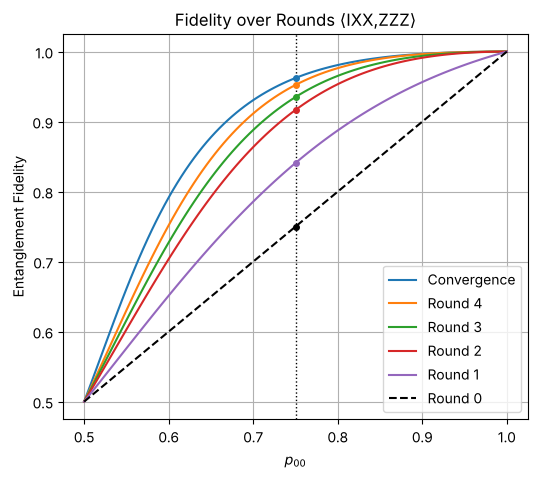

p00 = 0.85: fidelity after round 4 = 0.9897, total success probability = 0.2374, F_star = 0.9913
p00 = 0.75: fidelity after round 4 = 0.9524, total success probability = 0.0832, F_star = 0.9623
p00 = 0.65: fidelity after round 4 = 0.8466, total success probability = 0.0285, F_star = 0.8778
p00 = 0.55: fidelity after round 4 = 0.6304, total success probability = 0.0109, F_star = 0.6611


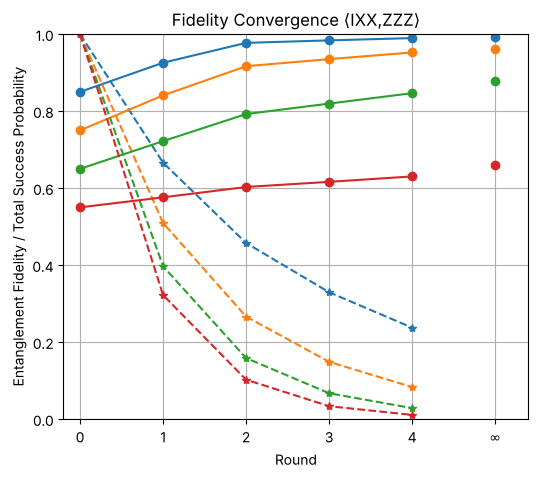

In [8]:
F, P, F_conv = sweep([L_star(p00, 2) for p00 in p00_vals], q0_depol, max_round=4)

plot_fidelity_vs_p00(F, [4, 3, 2, 1], F_conv, 'Fidelity over Rounds ⟨IXX,ZZZ⟩', 'fig6_left.png')
plot_fidelity_and_total_success(F, P, F_conv, 'Fidelity Convergence ⟨IXX,ZZZ⟩', 'fig6_right.png')

### Fig. 7: three and four carriers

p00 = 0.75: Convergence 0.989711, Round 4 0.966832, Round 3 0.942727, Round 2 0.915908, Round 1 0.840909, Round 0 0.750000


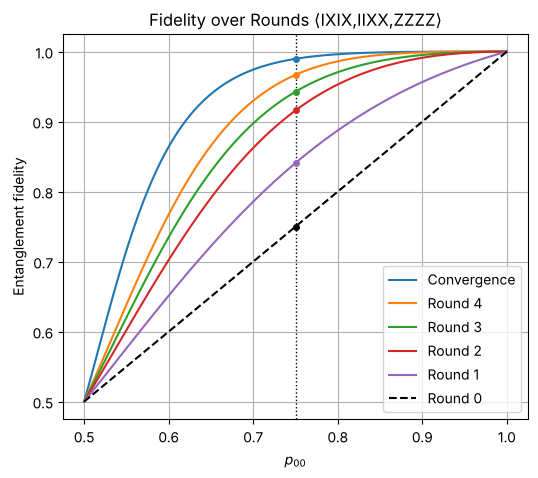

p00 = 0.75: Convergence 0.997233, Round 4 0.957035, Round 3 0.928919, Round 2 0.897249, Round 1 0.829498, Round 0 0.750000


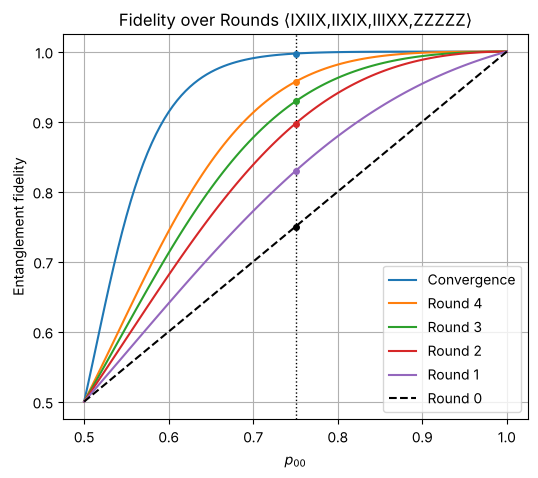

p00 = 0.75: Convergence 0.948469, Round 4 0.947989, Round 3 0.943435, Round 2 0.938840, Round 1 0.853139, Round 0 0.750000


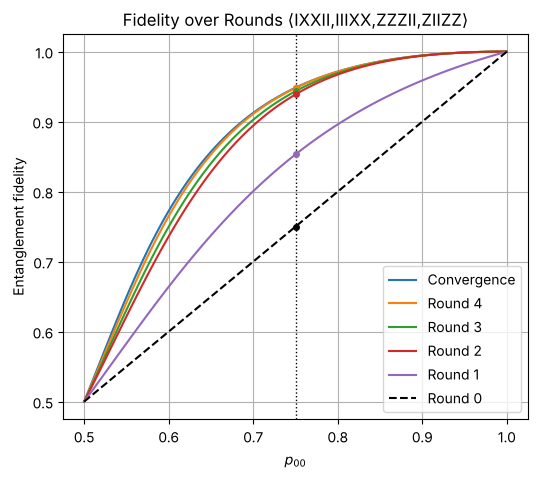

In [9]:
panels = [
    ('fig7a.png', 'Fidelity over Rounds ⟨IXIX,IIXX,ZZZZ⟩', [L_star(p00, 3) for p00 in p00_vals]),
    ('fig7b.png', 'Fidelity over Rounds ⟨IXIIX,IIXIX,IIIXX,ZZZZZ⟩', [L_star(p00, 4) for p00 in p00_vals]),
    ('fig7c.png', 'Fidelity over Rounds ⟨IXXII,IIIXX,ZZZII,ZIIZZ⟩', [L_pairwise(p00) for p00 in p00_vals]),
]
for filename, title, L_list in panels:
    F, P, F_conv = sweep(L_list, q0_depol, max_round=4)
    plot_fidelity_vs_p00(F, [4, 3, 2, 1], F_conv, title, filename, ylabel='Entanglement fidelity')

### Fig. 8: maximum convergent fidelity vs number of carriers

$F_\star$ is the first entry of the dominant eigenvector of $L_m$, normalized to unit sum, Eq. (56).
For $m = 0$ there is no purification, so $F_\star = p_{00}$.

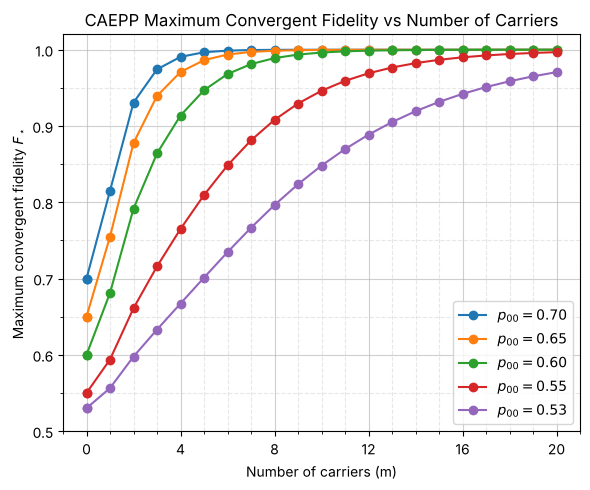

In [10]:
ps = [0.70, 0.65, 0.60, 0.55, 0.53]
ms = np.arange(0, 21)

plt.figure(figsize=(6, 5))
for p in ps:
    Fvals = [p] + [fixed_point(L_star(p, m))[0] for m in ms[1:]]
    line, = plt.plot(ms, Fvals, marker='o', label=rf"$p_{{00}} = {p:.2f}$")
    plt.scatter(ms[0], Fvals[0], color=line.get_color(), zorder=5)

plt.xlabel("Number of carriers (m)")
plt.ylabel("Maximum convergent fidelity $F_\\star$")
plt.title("CAEPP Maximum Convergent Fidelity vs Number of Carriers")
plt.ylim(0.5, 1.02)
ax = plt.gca()
ax.xaxis.set_major_locator(MultipleLocator(4))
ax.xaxis.set_minor_locator(MultipleLocator(1))
ax.yaxis.set_major_locator(MultipleLocator(0.1))
ax.yaxis.set_minor_locator(MultipleLocator(0.05))
plt.grid(True, which='major', linestyle='-', alpha=0.6)
plt.grid(True, which='minor', linestyle='--', alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig('fig8.png', bbox_inches='tight', dpi=600)
plt.show()

## Noisy local operations (Fig. 11)

One successful round of the CAEPP (Fig. 10(a), register carrier, $A$, $B$) and of the two-pair TWEPP (Fig. 10(b), register $A_0$, $A_1$, $B_0$, $B_1$) is computed with density matrices.
Every pair is $\phi^+$ with one half sent through a depolarizing channel with $p_{00} \in \{0.6, 0.7, 0.8, 0.9\}$, and the carrier goes through the same channel.
The noise parameters are as follows.
- $r$ is the memory depolarizing rate. Each memory qubit ($A$ and $B$ in the CAEPP, all four qubits in the TWEPP) suffers $X$, $Y$, or $Z$ with probability $r/3$ each, once before the round. This is the channel $\mathcal{D}_e$ of Eq. (26) with $e = 4r/3$.
- $f$ is the measurement flip rate of Eq. (27), applied to every measured outcome.
- `e_cnot` is the rate of a two-qubit depolarizing error after each CNOT. It is used only in the supplementary cell at the end.

In [11]:
# Single-qubit operators
I = np.eye(2, dtype=complex)
X = np.array([[0, 1], [1, 0]], dtype=complex)
Y = np.array([[0, -1j], [1j, 0]], dtype=complex)
Z = np.array([[1, 0], [0, -1]], dtype=complex)

def RX(theta):
    return np.cos(theta/2)*I - 1j*np.sin(theta/2)*X

def pauli_kraus_from_p00(p00):
    # Depolarizing channel: I with probability p00, and Z, X, Y with probability (1-p00)/3 each
    p_rest = (1 - p00)/3
    return [np.sqrt(p00)*I, np.sqrt(p_rest)*Z, np.sqrt(p_rest)*X, np.sqrt(p_rest)*Y]

def depol_kraus_from_rate(r):
    # Memory depolarizing rate r: X, Y, Z with probability r/3 each
    return pauli_kraus_from_p00(1 - r)

def apply_twoqubit_depol_N(rho, N, q1, q2, p):
    # (1-p) rho + (p/15) sum over the 15 non-identity Paulis on qubits q1, q2 (bit 0 = LSB)
    if p == 0:
        return rho
    paul = [I, X, Y, Z]
    def embed_two_qubit_op(P1, P2):
        ops = [P1 if b == q1 else P2 if b == q2 else I for b in range(N)]
        Op = ops[N-1]
        for k in range(N-2, -1, -1):
            Op = np.kron(Op, ops[k])
        return Op
    out = (1 - p) * rho
    w = p / 15.0
    for P1 in paul:
        for P2 in paul:
            if (P1 is I) and (P2 is I):
                continue
            Op = embed_two_qubit_op(P1, P2)
            out += w * (Op @ rho @ Op.conj().T)
    return out

phi = (np.kron([1, 0], [1, 0]) + np.kron([0, 1], [0, 1]))/np.sqrt(2)
rho_phi = np.outer(phi, phi.conj())

In [12]:
# CAEPP register: carrier = bit 0, A = bit 1, B = bit 2
def cnot_3(control, target):
    N = 3
    U = np.zeros((2**N, 2**N), dtype=complex)
    for i in range(2**N):
        bits = [(i >> k) & 1 for k in range(N)]
        nb = bits.copy()
        if bits[control] == 1:
            nb[target] ^= 1
        j = sum(nb[k] << k for k in range(N))
        U[j, i] = 1
    return U

def ptrace_carrier(rho):
    r = rho.reshape(4, 2, 4, 2)  # AB, c, AB', c'
    return r[:, 0, :, 0] + r[:, 1, :, 1]

U_mod_AB = np.kron(RX(+np.pi/2), RX(-np.pi/2))
CNOT_A_to_c = cnot_3(1, 0)
CNOT_B_to_c = cnot_3(2, 0)
proj0 = np.array([[1, 0], [0, 0]], dtype=complex)
proj1 = np.array([[0, 0], [0, 1]], dtype=complex)
M0 = np.kron(np.eye(4), proj0)
M1 = np.kron(np.eye(4), proj1)

def caepp_round(p00, r=0.0, f=0.0, e_cnot=0.0):
    # Fidelity after one successful CAEPP round (Fig. 10(a))
    Ks_ch = pauli_kraus_from_p00(p00)
    # 1) Share phi+ over the channel (B only)
    rho0 = sum(np.kron(I, K) @ rho_phi @ np.kron(I, K).conj().T for K in Ks_ch)
    # 2) Memory depolarization on A, then on B
    Ks_mem = depol_kraus_from_rate(r)
    rho_tmp = sum(np.kron(Ka, I) @ rho0 @ np.kron(Ka, I).conj().T for Ka in Ks_mem)
    rho_mem = sum(np.kron(I, Kb) @ rho_tmp @ np.kron(I, Kb).conj().T for Kb in Ks_mem)
    # 3) Pre-processing, carrier in |0>, encoding CNOT (A -> c), carrier transmission, decoding CNOT (B -> c)
    rho_mod = U_mod_AB @ rho_mem @ U_mod_AB.conj().T
    rho_cAB = np.kron(rho_mod, proj0)
    rho1 = apply_twoqubit_depol_N(CNOT_A_to_c @ rho_cAB @ CNOT_A_to_c.conj().T, 3, 1, 0, e_cnot)
    rho2 = sum(np.kron(np.eye(4), K) @ rho1 @ np.kron(np.eye(4), K).conj().T for K in Ks_ch)
    rho3 = apply_twoqubit_depol_N(CNOT_B_to_c @ rho2 @ CNOT_B_to_c.conj().T, 3, 2, 0, e_cnot)
    # 4) Keep when the reported outcome is 0 (true outcome flipped with probability f)
    sigma = (1 - f) * (M0 @ rho3 @ M0) + f * (M1 @ rho3 @ M1)
    rho_post = ptrace_carrier(sigma) / np.trace(sigma).real
    return np.real(phi.conj() @ (rho_post @ phi))

In [13]:
# TWEPP register: |A0, A1, B0, B1> = bits 3, 2, 1, 0
def kron4(a3, a2, a1, a0):
    return np.kron(np.kron(np.kron(a3, a2), a1), a0)

def cnot_4(control, target):
    U = np.zeros((16, 16), dtype=complex)
    for i in range(16):
        bits = [(i >> k) & 1 for k in range(4)]
        nb = bits.copy()
        if bits[control] == 1:
            nb[target] ^= 1
        j = sum(nb[k] << k for k in range(4))
        U[j, i] = 1
    return U

def idx(a0, a1, b0, b1):
    return (a0 << 3) | (a1 << 2) | (b0 << 1) | b1

# Two phi+ pairs in the ordering [A0, A1, B0, B1]
psi_4 = np.zeros(16, dtype=complex)
for a0, b0 in ((0, 0), (1, 1)):
    for a1, b1 in ((0, 0), (1, 1)):
        psi_4[idx(a0, a1, b0, b1)] += 0.5
rho_two_pairs = np.outer(psi_4, psi_4.conj())

# Projectors onto the outcomes of A1 and B1
P_0 = np.array([[1, 0], [0, 0]])
P_1 = np.array([[0, 0], [0, 1]])
P00 = kron4(np.eye(2), P_0, np.eye(2), P_0)
P01 = kron4(np.eye(2), P_0, np.eye(2), P_1)
P10 = kron4(np.eye(2), P_1, np.eye(2), P_0)
P11 = kron4(np.eye(2), P_1, np.eye(2), P_1)

U_CN_A = cnot_4(3, 2)  # A0 -> A1
U_CN_B = cnot_4(1, 0)  # B0 -> B1

def apply_channel_qubit(rho, Ks, bit):
    if bit == 0: ops = [kron4(np.eye(2), np.eye(2), np.eye(2), K) for K in Ks]
    elif bit == 1: ops = [kron4(np.eye(2), np.eye(2), K, np.eye(2)) for K in Ks]
    elif bit == 2: ops = [kron4(np.eye(2), K, np.eye(2), np.eye(2)) for K in Ks]
    else: ops = [kron4(K, np.eye(2), np.eye(2), np.eye(2)) for K in Ks]
    out = np.zeros_like(rho)
    for Op in ops:
        out += Op @ rho @ Op.conj().T
    return out

def reduce_to_A0B0(rho4):
    rho_AB = np.zeros((4, 4), dtype=complex)
    for a0 in (0, 1):
        for b0 in (0, 1):
            for a0p in (0, 1):
                for b0p in (0, 1):
                    val = 0.0 + 0.0j
                    for a1 in (0, 1):
                        for b1 in (0, 1):
                            val += rho4[idx(a0, a1, b0, b1), idx(a0p, a1, b0p, b1)]
                    rho_AB[(a0 << 1) | b0, (a0p << 1) | b0p] = val
    return rho_AB

def twepp_round(p00, r=0.0, f=0.0, e_cnot=0.0):
    # Fidelity after one successful two-pair TWEPP round (Fig. 10(b))
    Ks_ch = pauli_kraus_from_p00(p00)
    rho = rho_two_pairs.copy()
    # 1) Transmit B0 (bit 1) and B1 (bit 0)
    rho = apply_channel_qubit(rho, Ks_ch, 1)
    rho = apply_channel_qubit(rho, Ks_ch, 0)
    # 2) Memory depolarization on all four qubits
    Ks_mem = depol_kraus_from_rate(r)
    for bit in (3, 2, 1, 0):
        rho = apply_channel_qubit(rho, Ks_mem, bit)
    # 3) Bilateral CNOTs A0 -> A1 and B0 -> B1
    rho = apply_twoqubit_depol_N(U_CN_A @ rho @ U_CN_A.conj().T, 4, 3, 2, e_cnot)
    rho = apply_twoqubit_depol_N(U_CN_B @ rho @ U_CN_B.conj().T, 4, 1, 0, e_cnot)
    # 4) Keep when the reported outcomes of A1 and B1 agree (each flipped with probability f)
    w_eq = (1 - f)**2 + f**2
    w_uneq = 2*f*(1 - f)
    sigma = w_eq*(P00 @ rho @ P00 + P11 @ rho @ P11) + w_uneq*(P01 @ rho @ P01 + P10 @ rho @ P10)
    rho_AB = reduce_to_A0B0(sigma) / np.trace(sigma).real
    return np.real(phi.conj() @ (rho_AB @ phi))

In [14]:
p00_list = [0.9, 0.8, 0.7, 0.6]
colors = {0.9: 'C3', 0.8: 'C2', 0.7: 'C1', 0.6: 'C0'}
x = np.linspace(0.0, 0.05, 51)

def plot_caepp_vs_twepp(noise, xlabel, title, filename):
    # noise(v) gives the noise parameters at x = v. CAEPP solid, TWEPP dashed.
    # The dot marks the input fidelity p00, and the arrow the CAEPP fidelity without noise.
    F_car = {p00: np.array([caepp_round(p00, **noise(v)) for v in x]) for p00 in p00_list}
    F_tw = {p00: np.array([twepp_round(p00, **noise(v)) for v in x]) for p00 in p00_list}
    plt.figure(figsize=(6, 5))
    for p00 in p00_list:
        plt.plot(x, F_car[p00], '-', color=colors[p00])
        plt.plot(x, F_tw[p00], '--', color=colors[p00])
        plt.plot([0.0], [p00], 'o', color=colors[p00], markersize=4, zorder=5)
        plt.annotate('', xy=(0.0, F_car[p00][0]), xytext=(0.0, p00),
                     arrowprops=dict(arrowstyle='->', color=colors[p00], lw=1.5, shrinkA=0, shrinkB=0))
    plt.xlabel(xlabel)
    plt.ylabel('Entanglement fidelity')
    plt.title(title)
    plt.grid(True)
    plt.ylim(0.5, 1.0)
    plt.savefig(filename, bbox_inches='tight', dpi=600)
    plt.show()
    return F_car, F_tw

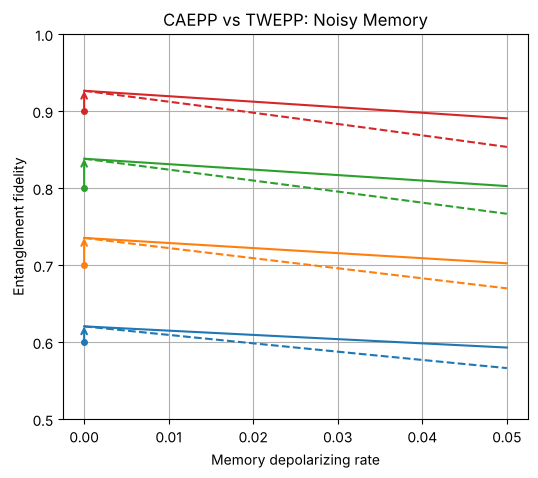

In [15]:
# Fig. 11(a): memory noise
plot_caepp_vs_twepp(lambda v: dict(r=v), 'Memory depolarizing rate',
                    'CAEPP vs TWEPP: Noisy Memory', 'fig11a.png');

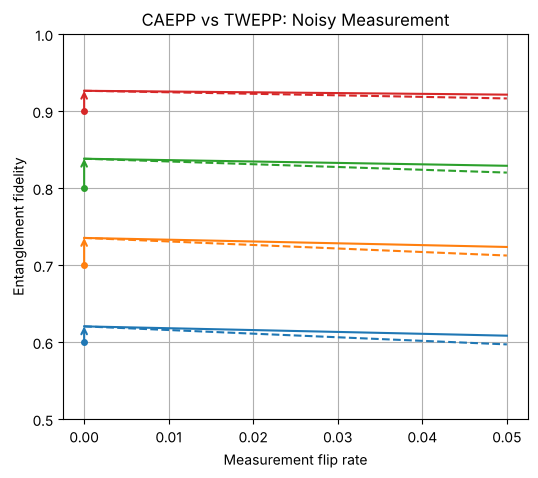

In [16]:
# Fig. 11(b): measurement noise
plot_caepp_vs_twepp(lambda v: dict(f=v), 'Measurement flip rate',
                    'CAEPP vs TWEPP: Noisy Measurement', 'fig11b.png');

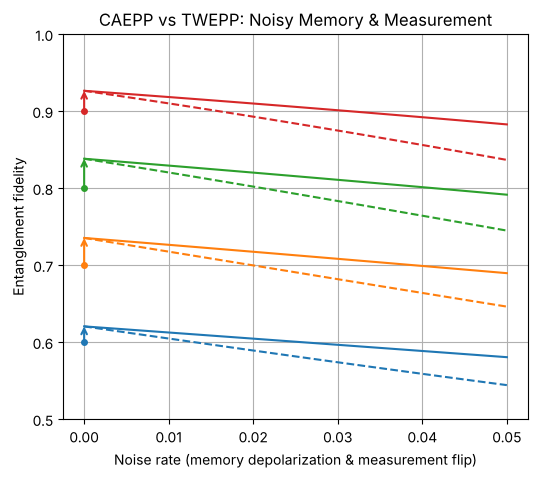

In [17]:
# Fig. 11(c): memory and measurement noise with r = f
plot_caepp_vs_twepp(lambda v: dict(r=v, f=v), 'Noise rate (memory depolarization & measurement flip)',
                    'CAEPP vs TWEPP: Noisy Memory & Measurement', 'fig11c.png');

## Supplementary: noisy CNOT gates (not a figure in the paper)

Sec. VI-C states that noise on the CNOT gates affects the CAEPP and TWEPPs equally.
With a two-qubit depolarizing error of rate `e_cnot` after each CNOT, the two fidelities coincide, so the dashed curves lie under the solid ones.

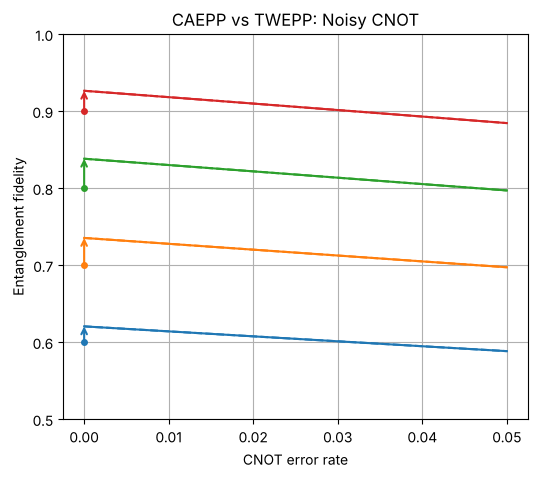

max |F_CAEPP - F_TWEPP| = 6.661338147750939e-16


In [18]:
F_car, F_tw = plot_caepp_vs_twepp(lambda v: dict(e_cnot=v), 'CNOT error rate',
                                  'CAEPP vs TWEPP: Noisy CNOT', 'supp_cnot.png')
print('max |F_CAEPP - F_TWEPP| =', max(np.max(np.abs(F_car[p00] - F_tw[p00])) for p00 in p00_list))